# Reto 2 — Feature engineering y pipeline de preparación

**Malackathon 2026 · Mercedes-Benz "Clustering the Star"**

Objetivo: transformar la tabla cliente–vehículo en **una fila por cliente** con las variables que realmente sirven para segmentar, y encapsular todo el proceso en un **pipeline de scikit-learn** reproducible. Las decisiones se apoyan en la evidencia del notebook `01_eda.ipynb`.

Estructura:
1. Carga
2. Features derivadas a nivel vehículo
3. Agregación a nivel cliente
4. Pipeline de transformación (imputación, outliers, codificación y escalado)
5. Ejecución y validación
6. Listado de features seleccionadas y derivadas
7. Exportación para el Reto 3

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, OneToOneFeatureMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")

## 1. Carga

In [2]:
CSV_NAME = "datos_reto_mercedes_benz_malackathon.csv"
DATA = next(p for p in (Path(CSV_NAME), Path("..") / CSV_NAME) if p.exists())
OUT_DIR = DATA.parent / "data" / "processed"

raw = pd.read_csv(DATA, index_col=0, dtype={"zipcode": str})
print("Filas:", f"{len(raw):,}", "| clientes:", f"{raw['client_id'].nunique():,}")

Filas: 302,850 | clientes: 173,456


## 2. Features derivadas a nivel vehículo

Antes de agregar por cliente se calculan las variables que dependen de cada vehículo:

| Feature | Cálculo | Motivo |
|---|---|---|
| `vehicle_age_years` | (fecha de referencia − `date_of_first_registration`) / 365,25 | Feature derivada sugerida por el enunciado; base de planes de mantenimiento y renovación |
| `workshop_visits_per_year` | `workshop_visits_warranty_goodwill` / max(`vehicle_age_years`, 1) | Normaliza las visitas por el tiempo: 4 visitas en 1 año no es lo mismo que en 8. El máximo con 1 evita dividir por casi 0 en coches nuevos |
| `engine_filled` | `engine_concept` completado (ver abajo) | Necesaria para medir la electrificación |
| `is_plugin` | 1 si eléctrico o híbrido enchufable | Señal directa para ofertas EV/PHEV |
| `has_telemetry_row` | 1 si el vehículo tiene algún dato de telemetría | Sustituye a la telemetría (~60 % nulos) por una señal de "cliente conectado" |
| `segment` | `model_class` agrupada en compacto / medio / premium / comercial | 42 clases son demasiadas para codificar; el segmento resume el posicionamiento del cliente |

**Fecha de referencia:** la matriculación más reciente del dataset, para que el cálculo sea reproducible y no dependa del día en que se ejecute.

**Nota sobre `workshop_visits_warranty_goodwill`:** es un dato **por vehículo** (varía dentro de un mismo cliente en más de 38.000 casos), por eso las visitas por año se calculan por vehículo y luego se promedian por cliente.

**Completado de `engine_concept` (44 % nulos):** cuando falta `engine_concept`, también falta siempre `fuel_type` (crosstab de la sección 4.1 del EDA), así que no sirve para completarlo. Se usa la denominación comercial `vehicle_type` en dos pasos:
1. **Búsqueda por `vehicle_type`:** se asigna la motorización más frecuente de ese mismo modelo entre las filas que sí la tienen (validado abajo con una partición de control).
2. **Reglas por nombre** para modelos que nunca tienen el dato: `EQ*` o "electric" → eléctrico; sufijo `e`/`de`, "hybrid" o "E Performance" → híbrido enchufable.

Lo que sigue sin dato se resuelve a nivel cliente (sección 3): `pct_plugin = 0` y el indicador `engine_unknown = 1`.

In [3]:
TELEMETRY = ["trip_distance_average", "trip_distance_median", "trip_distance_mode", "trip_distance_all_counter",
             "operating_hours_total", "fuel_consumption_average", "speed_average", "speed_median",
             "speed_mode", "speed_all_counter"]
PLUGIN = {"ELECTRIC", "PLUGIN_HYBRID"}
REFERENCE_DATE = pd.to_datetime(raw["date_of_first_registration"]).max()

SEGMENTS = {
    "compacto": ["A-Class", "A-Class/CLA-Class", "B-Class", "B-/GLA-/GLB-Class", "CLA-Class", "GLA-Class",
                 "EQA-/EQB-Class", "fortwo / forfour"],
    "medio": ["C-Class", "CLE-Class", "CLK-Class", "E-Class", "E-Class Coupé/Cabriolet", "GLC-Class",
              "SLK-/SLC-Class", "SLK-Class", "SLK-C", "EQC-Class", "EQE-Class"],
    "premium": ["S-Class", "S-Class Coupé/Cabriolet", "CL-Class", "CLS-Class", "Maybach", "G-Class",
                "GLE-/GLS-Class", "GLE-Class", "M-/GL-/GLE-/GLS-Class", "M-/GL-Class", "M-Class", "R-Class",
                "SL-Class", "AMG GT", "AMG GT 4-Door", "AMG ONE", "SLR McLaren", "SLS AMG", "EQS-Class"],
    "comercial": ["Citan", "Sprinter", "V-Class / Vito", "Viano/Vito", "X-Class", "T-Class", "EQT-Class",
                  "EQV-Class"],
}
CLASS_TO_SEGMENT = {cls: seg for seg, classes in SEGMENTS.items() for cls in classes}
unmapped = set(raw["model_class"].dropna()) - set(CLASS_TO_SEGMENT)
print("Clases sin segmento asignado:", unmapped or "ninguna")

Clases sin segmento asignado: ninguna


In [4]:
def mode_by(df, target, key):
    """Most frequent value of `target` for each value of `key` (rows with both present)."""
    known = df.dropna(subset=[target, key])
    return (known.groupby([key, target]).size().reset_index(name="n")
            .sort_values("n", ascending=False).drop_duplicates(key).set_index(key)[target])


def fill_engine(df):
    lookup = mode_by(df, "engine_concept", "vehicle_type")
    engine = df["engine_concept"].fillna(df["vehicle_type"].map(lookup))
    vt = df["vehicle_type"].fillna("")
    is_ev = vt.str.contains(r"\bEQ[A-Z]?\b") | vt.str.contains("electric", case=False)
    is_phev = vt.str.contains(r"\b\d{3} d?e\b") | vt.str.contains("hybrid|e performance", case=False)
    return engine.mask(engine.isna() & is_ev, "ELECTRIC").mask(engine.isna() & is_phev, "PLUGIN_HYBRID")


def add_vehicle_features(df, reference_date=REFERENCE_DATE):
    df = df.copy()
    reg = pd.to_datetime(df["date_of_first_registration"], errors="coerce")
    age = (reference_date - reg).dt.days / 365.25
    # 1.4 % sin fecha: mediana de antigüedad de su serie de modelo (y global si la serie no tiene dato)
    age = age.fillna(age.groupby(df["model_series"]).transform("median")).fillna(age.median())
    model_class = df["model_class"].fillna(df["model_series"].map(mode_by(df, "model_class", "model_series")))
    engine = fill_engine(df)
    return df.assign(
        vehicle_age_years=age,
        workshop_visits_per_year=df["workshop_visits_warranty_goodwill"] / np.maximum(age, 1),
        engine_filled=engine,
        is_plugin=engine.isin(PLUGIN).astype(float).where(engine.notna()),
        has_telemetry_row=df[TELEMETRY].notna().any(axis=1),
        segment=model_class.map(CLASS_TO_SEGMENT),
    )


vehicles = add_vehicle_features(raw)
vehicles[["vehicle_age_years", "workshop_visits_per_year", "is_plugin", "has_telemetry_row"]].describe().T

,count,mean,std,min,25%,50%,75%,max
vehicle_age_years,"302,850.000",5.116,3.287,0.000,2.542,4.720,7.113,39.715
workshop_visits_per_year,"302,850.000",0.458,0.675,0.000,0.000,0.158,0.713,12.074
is_plugin,"249,633.000",0.235,0.424,0.000,0.000,0.000,0.000,1.000


In [5]:
# Validación del completado de motorización: se oculta la mitad de los datos conocidos y se predice con la otra mitad
known = raw[raw["engine_concept"].notna()]
holdout = np.random.default_rng(42).random(len(known)) < 0.5
lookup = mode_by(known[~holdout], "engine_concept", "vehicle_type")
pred = known.loc[holdout, "vehicle_type"].map(lookup)
covered = pred.notna()
print(f"Búsqueda por vehicle_type — cobertura: {covered.mean():.1%} | acierto: "
      f"{(pred[covered] == known.loc[holdout, 'engine_concept'][covered]).mean():.1%}")

pd.DataFrame({
    "antes (engine_concept)": raw["engine_concept"].isna().mean() * 100,
    "después (engine_filled)": vehicles["engine_filled"].isna().mean() * 100,
}, index=["% nulos"]).round(1)

Búsqueda por vehicle_type — cobertura: 99.9% | acierto: 95.5%


,antes (engine_concept),después (engine_filled)
% nulos,44.400,17.600


## 3. Agregación a nivel cliente

El EDA mostró que el dataset tiene una fila por **par cliente–vehículo**. Para segmentar clientes hay que agregar. Reglas:

- Atributos del cliente (edad, antigüedad, financiación, consentimientos, zona): se toma el valor del cliente.
- Atributos del vehículo: se priorizan los **vehículos actuales**, porque son los que definen la relación hoy; si el cliente no tiene ninguno actual (~10 %), se usan todos.
- Se descartan los clientes sin `months_as_mb_customer` (4 filas, impacto despreciable).
- **`pct_plugin` desconocido** (clientes sin ninguna motorización recuperable, ~11 %): se imputa **0** y se marca con `engine_unknown = 1`. La búsqueda por modelo y las reglas de nombre no encontraron ninguna marca de eléctrico en sus vehículos, así que "no enchufable" es la hipótesis con más evidencia; el indicador permite que el modelo distinga a estos clientes y deja constancia de la incertidumbre.

In [6]:
AGE_ORDER = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
CONSENTS = ["consent_phone_communication_channel", "consent_epost_communication_channel",
            "consent_post_communication_channel"]


def prefer_current(vehicles, column, agg):
    """Aggregate `column` over current vehicles, falling back to all vehicles for clients without any."""
    current = vehicles[vehicles["is_current_vehicle"]].groupby("client_id")[column].agg(agg)
    every = vehicles.groupby("client_id")[column].agg(agg)
    return current.reindex(every.index).fillna(every)


def main_segment(vehicles):
    def top(v):
        return (v.dropna(subset=["segment"]).groupby(["client_id", "segment"]).size().reset_index(name="n")
                .sort_values("n", ascending=False).drop_duplicates("client_id").set_index("client_id")["segment"])
    every = top(vehicles)
    return top(vehicles[vehicles["is_current_vehicle"]]).reindex(every.index).fillna(every)


def build_client_features(raw):
    v = add_vehicle_features(raw)
    g = v.groupby("client_id")
    first = g.first()
    n_rows = g.size()
    n_current_rows = g["is_current_vehicle"].sum()
    population = first["population"].mask(first["population"] == 0)  # 0 habitantes es incoherente → nulo
    # Sin ninguna motorización recuperable: las reglas no detectaron nada eléctrico → 0, marcado con engine_unknown
    pct_plugin = g["is_plugin"].mean()

    clients = pd.DataFrame({
        # --- features del modelo
        "age_ordinal": first["age_range"].map({a: i for i, a in enumerate(AGE_ORDER)}),
        "months_as_mb_customer": first["months_as_mb_customer"],
        "n_current_vehicles": first["currently_connected_vehicles"],
        "has_past_vehicles": (n_rows > n_current_rows).astype(int),
        "vehicle_age_years": prefer_current(v, "vehicle_age_years", "mean"),
        "workshop_visits_per_year": g["workshop_visits_per_year"].mean(),
        "consent_level": first[CONSENTS].astype(int).sum(axis=1) / 3,
        "pct_plugin": pct_plugin.fillna(0),
        "engine_unknown": pct_plugin.isna().astype(int),
        "has_telemetry": g["has_telemetry_row"].any().astype(int),
        "is_b2b": g["role_type"].agg(lambda s: (s == "B2B").any()).astype(int),
        "purchasing_power_per_household_eur": first["purchasing_power_per_household_eur"],
        "population": population,
        "finance_leasing_status": first["finance_leasing_status"],
        "main_segment": main_segment(v),
        # --- solo para perfilar segmentos (Reto 4), no entran en el modelo
        "country_code": first["country_code"],
        "gender_derived": first["gender_derived"].fillna("unknown"),
        "age_range": first["age_range"],
        "n_vehicles_total": g["vehicle_id"].nunique(),
        "trip_distance_average": g["trip_distance_average"].mean(),
        "speed_average": g["speed_average"].mean(),
        "operating_hours_total": g["operating_hours_total"].mean(),
    })
    return clients[clients["months_as_mb_customer"].notna()]


clients = build_client_features(raw)
print("Clientes:", f"{len(clients):,}")
clients.head()

Clientes: 173,454


,age_ordinal,months_as_mb_customer,n_current_vehicles,has_past_vehicles,vehicle_age_years,workshop_visits_per_year,consent_level,pct_plugin,engine_unknown,has_telemetry,is_b2b,purchasing_power_per_household_eur,population,finance_leasing_status,main_segment,country_code,gender_derived,age_range,n_vehicles_total,trip_distance_average,speed_average,operating_hours_total
client_id,,,,,,,,,,,,,,,,,,,,,,
0000eb1785b60456d8ca6059563d61ad9ec480b63d69f616478bc9eb50510d33,4,46.000,1,0,3.890,0.771,1.000,0.000,0,1,0,"61,750.030","6,433.000",never_active,compacto,AT,male,55-64,1,30.400,76.450,341.320
000144e39c02702f821f69beeb7036f40cf8505051050f38ea776337ef9b6f3c,2,36.000,1,1,3.031,0.660,0.333,0.000,0,1,0,"59,705.400","104,752.000",never_active,medio,AT,female,35-44,2,9.590,40.340,295.980
00017f3423e3110fffd0e920f7bc09af8be9e76afd000486fba5946417888eb5,3,3.000,1,1,0.252,0.000,1.000,0.000,0,1,0,"68,364.560","5,847.000",active_FL_only,premium,AT,male,45-54,2,18.010,69.550,41.610
0002237881f9c8edb669596513bd0fda1840f744be43826b88e7132d476e1a69,5,33.000,1,0,2.817,1.065,1.000,0.000,0,1,0,NaN,NaN,never_active,medio,CH,unknown,65+,1,29.860,76.520,188.010
00025c8e89802884b50161dd460faab34f9cff05781f17d62cb8167c75278383,2,43.000,1,1,2.062,0.586,1.000,0.000,0,1,0,"125,007.580","7,354.000",active_FL_only,compacto,CH,male,35-44,2,11.780,41.465,824.130


In [7]:
clients.isna().mean().mul(100).round(2).loc[lambda s: s > 0].to_frame("% nulos tras agregar")

,% nulos tras agregar
purchasing_power_per_household_eur,8.850
population,8.850
main_segment,0.660
trip_distance_average,50.070
speed_average,48.650
operating_hours_total,46.020


**Interpretación**

- Tras agregar quedan nulos solo en poder adquisitivo y población (zonas sin datos socioeconómicos), `main_segment` (0,7 %) y las métricas de telemetría, que **no entran en el modelo**. `pct_plugin` ya no tiene nulos: los desconocidos valen 0 con `engine_unknown = 1`.
- La telemetría se resume en `has_telemetry`; sus métricas se conservan solo para describir los segmentos en el Reto 4, porque imputar el ~60 % de los valores inventaría la mayor parte de la información (criterio de los apuntes).

### ¿Imputar o eliminar?

El enunciado admite imputar o eliminar. Los apuntes recomiendan eliminar filas solo si afectan a **menos del 5 %** y los huecos son **aleatorios**. Se comprueba qué pasaría si se eliminara a los clientes con algún dato desconocido en las features del modelo:

In [8]:
unknown = (clients[["purchasing_power_per_household_eur", "population", "main_segment"]].isna().any(axis=1)
           | clients["engine_unknown"].eq(1))
print(f"Clientes que se eliminarían: {unknown.sum():,} ({unknown.mean():.1%})")

compare = ["months_as_mb_customer", "vehicle_age_years", "n_current_vehicles", "has_telemetry", "has_past_vehicles"]
profile = pd.DataFrame({
    "se quedan": clients.loc[~unknown, compare].mean(),
    "se eliminarían": clients.loc[unknown, compare].mean(),
})
segments = pd.crosstab(clients["main_segment"].fillna("sin dato"), unknown, normalize="columns").set_axis(
    ["se quedan", "se eliminarían"], axis=1).rename(index=lambda s: f"% segmento {s}")
pd.concat([profile, segments * 100]).round(2)

Clientes que se eliminarían: 33,083 (19.1%)


,se quedan,se eliminarían
months_as_mb_customer,36.390,23.320
vehicle_age_years,4.730,5.060
n_current_vehicles,1.070,0.900
has_telemetry,0.630,0.470
has_past_vehicles,0.330,0.200
% segmento comercial,8.920,20.130
% segmento compacto,38.500,28.490
% segmento medio,41.470,32.320
% segmento premium,11.120,15.570
% segmento sin dato,0.000,3.490


**Decisión: imputar.** Eliminar supondría perder casi **1 de cada 5 clientes** (lejos del umbral del 5 %), y no al azar: los eliminados son sobre todo **clientes recientes** (menos meses con la marca), con menos telemetría, que aún no han renovado y con mucho más peso del **segmento comercial**. Eliminarlos sesgaría la segmentación y haría desaparecer justo grupos clave para captación y fidelización temprana. Solo se eliminan los 2 clientes sin antigüedad, que sí cumplen ambos criterios.

## 4. Pipeline de transformación

Todo el proceso, desde el CSV en bruto hasta la matriz que recibe K-Means, queda en un único `Pipeline`:

| Paso | Qué hace | Por qué |
|---|---|---|
| `client_features` | Features derivadas por vehículo + agregación por cliente (secciones 2–3) | Una fila por cliente |
| `country_impute` | Poder adquisitivo y población: mediana **por país** | Distribución bimodal Suiza/Austria (EDA, sección 5): la mediana global sería irreal para ambos |
| `log` | `log1p` en contadores, poder adquisitivo y población | Asimetría positiva fuerte (EDA); K-Means usa distancias y los extremos dominarían |
| `impute` | Mediana (red de seguridad) | Con los datos actuales no queda ningún nulo numérico en este punto; protege el pipeline si se aplica a otros datos (p. ej. submuestras del Reto avanzado 3) |
| `clip` | Recorte a los percentiles 1–99 | Outliers detectados en el EDA (visitas, contadores): se recortan en lugar de eliminar clientes |
| `scale` | `StandardScaler` | K-Means es sensible a la escala: todas las numéricas con media 0 y desviación 1 |
| `onehot` | Moda para el 0,7 % sin segmento + `OneHotEncoder` para `finance_leasing_status` y `main_segment`, quitando la categoría de referencia (`never_active`, `medio`) | Categóricas nominales sin orden: el label encoding inventaría distancias. La categoría más frecuente se elimina porque queda implícita (todas las demás a 0) y evita la correlación artificial entre dummies |
| binarias | Se mantienen en 0/1 | Ya están en una escala comparable |

`age_ordinal` se trata como numérica porque el rango de edad tiene **orden natural** (ordinal encoding).

In [9]:
COUNTRY_IMPUTE = ["purchasing_power_per_household_eur", "population"]
LOG_COLS = ["n_current_vehicles", "workshop_visits_per_year", "purchasing_power_per_household_eur", "population"]
NUM_COLS = ["age_ordinal", "months_as_mb_customer", "vehicle_age_years", "consent_level", "pct_plugin"] + LOG_COLS
BIN_COLS = ["has_past_vehicles", "has_telemetry", "is_b2b", "engine_unknown"]
CAT_COLS = ["finance_leasing_status", "main_segment"]


class GroupMedianImputer(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    """Fill `columns` with the median of their group (e.g. country), learned at fit time."""

    def __init__(self, columns, group):
        self.columns = columns
        self.group = group

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.medians_ = X.groupby(self.group)[self.columns].median()
        self.global_medians_ = X[self.columns].median()
        return self

    def transform(self, X):
        X = X.copy()
        group_medians = self.medians_.reindex(X[self.group]).set_axis(X.index)
        X[self.columns] = X[self.columns].fillna(group_medians).fillna(self.global_medians_)
        return X


class QuantileClipper(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    """Winsorize each column to the [lower, upper] quantiles learned at fit time."""

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.low_, self.high_ = X.quantile(self.lower), X.quantile(self.upper)
        return self

    def transform(self, X):
        return pd.DataFrame(X).clip(self.low_, self.high_, axis=1)


def log_transform(X):
    return X.assign(**{c: np.log1p(X[c]) for c in LOG_COLS})


numeric = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("clip", QuantileClipper(0.01, 0.99)),
    ("scale", StandardScaler()),
])

preprocess = ColumnTransformer([
    ("num", numeric, NUM_COLS),
    ("bin", "passthrough", BIN_COLS),
    ("onehot", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(drop=["never_active", "medio"], handle_unknown="ignore", sparse_output=False)),
    ]), CAT_COLS),
], remainder="drop", verbose_feature_names_out=False)

pipeline = Pipeline([
    ("client_features", FunctionTransformer(build_client_features)),
    ("country_impute", GroupMedianImputer(COUNTRY_IMPUTE, group="country_code")),
    ("log", FunctionTransformer(log_transform)),
    ("preprocess", preprocess),
]).set_output(transform="pandas")
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('client_features', ...), ('country_impute', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function bui...t 0x118d9c040>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, defaul

## 5. Ejecución y validación

In [10]:
X = pipeline.fit_transform(raw)
print("Matriz para K-Means:", X.shape)
print("Nulos restantes:", int(X.isna().sum().sum()))
X.describe().T[["mean", "std", "min", "max"]]

Matriz para K-Means: (173454, 19)
Nulos restantes: 0


,mean,std,min,max
age_ordinal,0.000,1.000,-1.976,1.364
months_as_mb_customer,-0.000,1.000,-1.657,2.806
vehicle_age_years,-0.000,1.000,-1.580,2.926
consent_level,-0.000,1.000,-2.553,0.458
pct_plugin,0.000,1.000,-0.533,2.084
n_current_vehicles,0.000,1.000,-2.524,2.776
workshop_visits_per_year,0.000,1.000,-1.041,2.787
purchasing_power_per_household_eur,0.000,1.000,-1.849,2.630
population,0.000,1.000,-2.251,2.636
has_past_vehicles,0.303,0.460,0.000,1.000


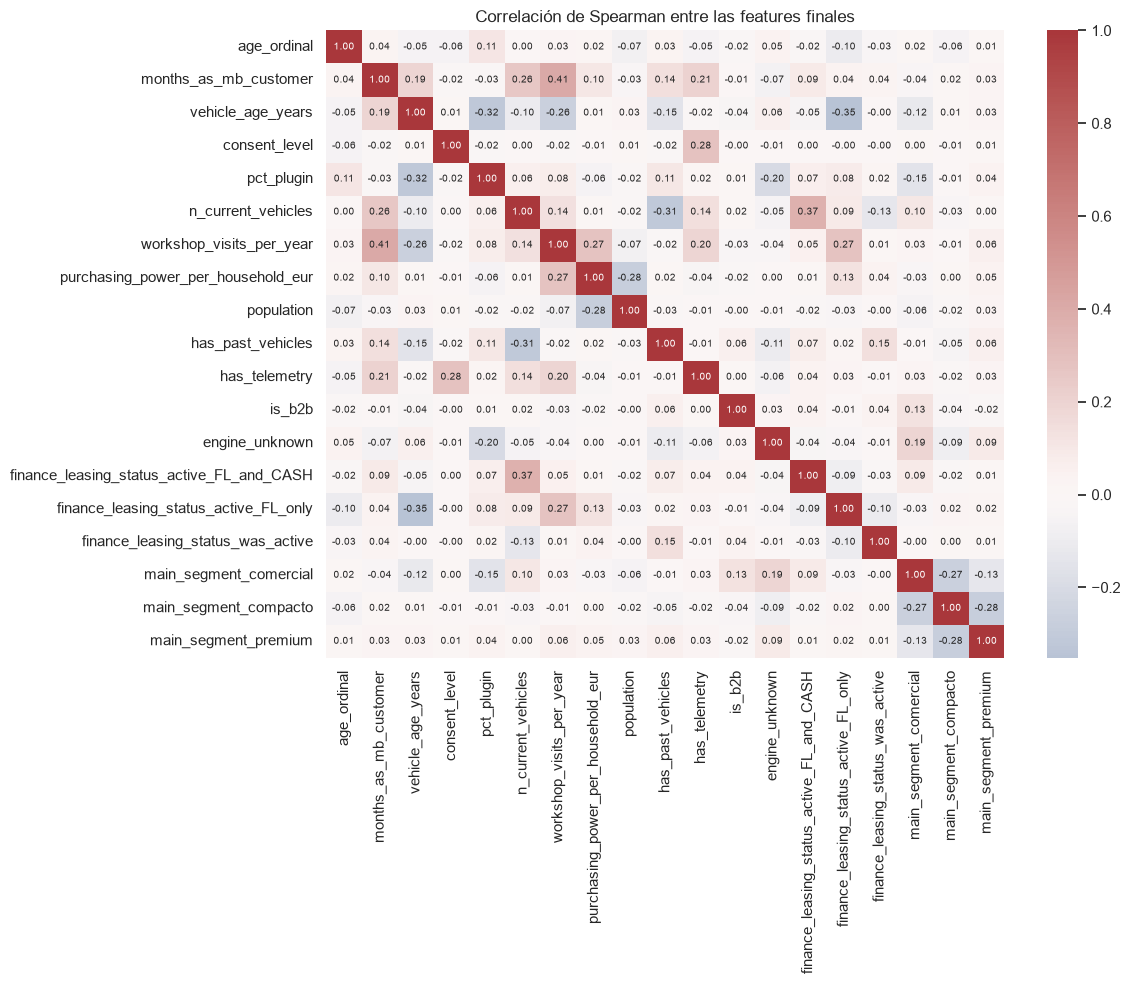

,,"ρ (> 0,8)"


In [11]:
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(X.corr(method="spearman"), cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlación de Spearman entre las features finales")
plt.tight_layout()
plt.show()

corr = X.corr(method="spearman")
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.8].to_frame("ρ (> 0,8)")

**Interpretación**

- La matriz final no tiene nulos y todas las numéricas quedan centradas y escaladas; binarias y one-hot se mantienen en 0/1.
- `pct_plugin` y `engine_unknown` se resuelven antes del pipeline (sección 3), por lo que no hay imputación por regresión que pueda inventar valores intermedios.
- La matriz de correlación verifica que no hay variables redundantes. En una primera versión, `has_commercial_vehicle` tenía ρ = 0,92 con `main_segment = comercial` y se eliminó para no contar dos veces lo mismo. Con el one-hot completo, `active_FL_only` y `never_active` tenían ρ = −0,86 (y `compacto` vs `medio`, −0,63): no es información de los clientes, sino que las dummies de una misma variable son excluyentes. Por eso se elimina la categoría de referencia de cada variable (la mayoritaria: `never_active` y `medio`); un cliente con todas las dummies del grupo a 0 pertenece a ella.

## 6. Listado de features

### 6.1 Features seleccionadas para el modelo

| Feature | Tipo | Tratamiento | Justificación de negocio |
|---|---|---|---|
| `age_ordinal` | Ordinal | 0–5 + escalado | Edad del cliente: guía el tipo de oferta y el tono de la comunicación |
| `months_as_mb_customer` | Numérica | Escalado | Antigüedad con la marca: base de las campañas de fidelización |
| `n_current_vehicles` | Numérica | log + escalado | Tamaño de la relación actual (de particular a flota) |
| `vehicle_age_years` | Numérica (**derivada**) | Escalado | Momento del ciclo de vida del coche: mantenimiento y renovación |
| `workshop_visits_per_year` | Numérica (**derivada**) | log + recorte + escalado | Intensidad de uso del taller: planes de mantenimiento |
| `consent_level` | Numérica (**derivada**) | Escalado | Alcance de las comunicaciones dirigidas |
| `pct_plugin` | Numérica (**derivada**) | 0 si desconocido + escalado | Afinidad con la electrificación: ofertas EV/PHEV |
| `engine_unknown` | Binaria (**derivada**) | 0/1 | Marca a los clientes sin motorización conocida, para que su `pct_plugin = 0` no se confunda con "no enchufable" seguro |
| `purchasing_power_per_household_eur` | Numérica | Mediana por país + log + escalado | Capacidad económica de la zona: ofertas premium o de entrada |
| `population` | Numérica | Mediana por país + log + escalado | Entorno urbano o rural del cliente |
| `has_past_vehicles` | Binaria (**derivada**) | 0/1 | Cliente que ya ha renovado o cambiado de vehículo con la marca |
| `has_telemetry` | Binaria (**derivada**) | 0/1 | Cliente con vehículo conectado: canal digital y servicios conectados |
| `is_b2b` | Binaria (**derivada**) | 0/1 | Relación de empresa o flota |
| `finance_leasing_status` | Nominal | One-hot sin `never_active` (referencia) | Relación con la financiación: ofertas de leasing |
| `main_segment` | Nominal (**derivada**) | One-hot sin `medio` (referencia) | Posicionamiento del cliente en la gama |

### 6.2 Variables descartadas del modelo

| Variable | Motivo |
|---|---|
| `client_id`, `vehicle_id`, `zipcode` | Identificadores (EDA, sección 6) |
| `model_series`, `vehicle_type`, `model_class` | Código sin magnitud / demasiadas categorías; resumidas en `main_segment` |
| `engine_concept`, `fuel_type` | Resumidas en `pct_plugin` |
| `product_group` | Resumida en `main_segment` (segmento comercial) |
| `has_commercial_vehicle` (derivada, descartada) | 1 si el cliente tiene algún vehículo comercial; redundante con `main_segment = comercial` (ρ = 0,92 en una primera versión del pipeline) |
| `role`, `role_type` | Resumidas en `is_b2b` (B2B ⇔ DRIVER) |
| `is_current_vehicle` | Usada en la agregación y en `has_past_vehicles` |
| `currently_connected_vehicles` | Renombrada como `n_current_vehicles` |
| `workshop_visits_warranty_goodwill` | Sustituida por su versión por año |
| Consentimientos individuales | Resumidos en `consent_level` |
| `purchasing_power_per_inhabitant_eur`, `purchasing_power_millions_eur`, `number_of_households` | Redundantes (ρ ≥ 0,96 con las conservadas) |
| Telemetría (`trip_*`, `speed_*`, `operating_hours_total`, `fuel_consumption_average`) | ~60 % nulos no aleatorios; resumida en `has_telemetry` y conservada solo para perfilar |
| `gender_derived` | Dato inferido, no declarado; solo para perfilar |
| `country_code` | Solo 2 mercados: partiría los clusters por país; ya influye vía la imputación por país y se usa para perfilar |

### 6.3 Features derivadas creadas

| Feature | Definición |
|---|---|
| `vehicle_age_years` | (fecha de referencia − fecha de primera matriculación) / 365,25, media de los vehículos actuales del cliente (o de todos si no tiene actuales). Fecha de referencia: la matriculación más reciente del dataset |
| `workshop_visits_per_year` | Por vehículo, visitas al taller / max(antigüedad, 1); media por cliente |
| `consent_level` | (consentimiento teléfono + ePost + correo postal) / 3 → 0, ⅓, ⅔ o 1 |
| `has_telemetry` | 1 si algún vehículo del cliente tiene algún dato de telemetría, 0 si no |
| `pct_plugin` | Proporción de vehículos eléctricos o híbridos enchufables, con la motorización completada por modelo (`vehicle_type`) y por reglas de nombre |
| `engine_unknown` | 1 si ninguno de sus vehículos tiene motorización recuperable (en ese caso `pct_plugin = 0`) |
| `has_past_vehicles` | 1 si el cliente tiene vehículos que ya no son actuales |
| `is_b2b` | 1 si tiene alguna relación B2B |
| `main_segment` | Segmento más frecuente de sus vehículos actuales: compacto, medio, premium o comercial |

## 7. Exportación para el Reto 3

Se guardan dos ficheros en `data/processed/` (no se suben al repositorio; se regeneran ejecutando este notebook):

- `X_model.csv`: matriz transformada que recibe K-Means.
- `client_features.csv`: features sin escalar + variables de perfilado, para interpretar los segmentos en el Reto 4.

In [12]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
X.to_csv(OUT_DIR / "X_model.csv")
clients.to_csv(OUT_DIR / "client_features.csv")
print("Guardado en", OUT_DIR.resolve())
print("X_model:", X.shape, "| client_features:", clients.shape)

Guardado en /Users/yusenliu/Documents/DEV/Github/Malackathon2026/data/processed
X_model: (173454, 19) | client_features: (173454, 22)
